# Taller: Análisis de Componentes Principales (PCA)


### Aprendizaje No Supervisado — Reducción de dimensionalidad con `StandardScaler` y `PCA`


**Pontificia Universidad Católica del Ecuador · Carrera de Ingeniería de Sistemas de Información**

**Asignatura:** Inteligencia Artificial · Sexto Semestre

**Nombre del estudiante:** Paúl Rosero

**Fecha:** 20-10-2026

> **Cómo usar este material:** este taller es una **guía de referencia en HTML**, no un notebook interactivo.
> Reproduce cada celda de código en tu propio Google Colab o Jupyter Notebook, en el mismo orden en que
> aparece: cada bloque usa los objetos creados en el anterior. Necesitas el archivo `spotify_audio_features.csv`.


## Objetivos del taller


Al finalizar este taller el estudiante será capaz de:

1. Explicar con datos reales por qué hay que **estandarizar** antes de aplicar PCA.
2. Aplicar `StandardScaler` + `PCA` en un `Pipeline` y elegir el número de componentes con la **varianza explicada**.
3. Interpretar los **loadings**, el **mapa PC1–PC2** y el **biplot**.
4. Entrenar el modelo final con el 100% de los datos, exportarlo con `joblib` y usarlo con canciones nuevas.


## Dataset (sintético, sin valores nulos)


**`spotify_audio_features.csv`** — 1 200 canciones de 8 géneros (150 por género), inspirado en Spotify Audio Features.
Los valores **no** provienen de la API real de Spotify.

| Variable | Rango | Qué mide |
| --- | --- | --- |
| `song_id` | 0 a 1 199 | Identificador: no entra en PCA |
| `genre` | 8 géneros | Texto: **no entra en PCA**, solo se usa para colorear |
| `danceability` | 0.07 a 1 | Qué tan bailable es |
| `energy` | 0 a 1 | Intensidad percibida |
| `loudness_db` | −28.7 a −5.0 dB | Volumen promedio |
| `speechiness` | 0 a 0.42 | Presencia de palabras habladas |
| `acousticness` | 0 a 1 | Qué tan acústica es |
| `instrumentalness` | 0 a 1 | Probabilidad de no tener voz |
| `liveness` | 0 a 0.41 | Presencia de público en vivo |
| `valence` | 0.07 a 1 | Positividad (alegría) musical |
| `tempo_bpm` | 80 a 170 | Pulsaciones por minuto |
| `duration_ms` | 121 265 a 238 049 | Duración en milisegundos |


## Estructura del taller


| Bloque | Tipo | Contenido |
| --- | --- | --- |
| A1 | Guiado | Carga y exploración |
| A2 | Guiado | Variables redundantes: matriz de correlaciones |
| A3 | Guiado | ¿Por qué estandarizar? Prueba sin escalar |
| A4 | Guiado | `Pipeline` escalar + PCA y varianza explicada |
| A5 | Guiado | Elegir k automáticamente con `n_components=0.80` |
| A6 | Guiado | Mapa de canciones PC1 vs. PC2 |
| A7 | Guiado | Loadings: qué hay dentro de cada componente |
| A8 | Guiado | Biplot |
| B1 | Autónomo | ¿Ritmo o timbre? Dos PCA por separado |
| B2 | Autónomo | Comparar la varianza explicada |
| B3 | Autónomo | Comparar los mapas y los loadings |
| C | Guiado | Entrenamiento final (100%), exportación y uso con canciones nuevas |


## Rúbrica de evaluación (10 puntos)


| Componente | Qué se evalúa | Puntos |
| --- | --- | --- |
| Bloques A1–A8 y C (guiados) | Reproducidos completos y sin errores en tu notebook | 1.5 |
| Bloque B1 (autónomo) | Código correcto: `X_ritmo`, `X_timbre` y los dos `Pipeline` entrenados | 2.0 |
| Bloque B2 (autónomo) | Código correcto (1.5) + tabla y respuestas de análisis (1.5) | 3.0 |
| Bloque B3 (autónomo) | Código correcto (1.5) + respuestas de análisis y reflexión (2.0) | 3.5 |
| **Total** |  | **10.0** |


# Parte A — Laboratorio Guiado: el Perfil Sonoro de las Canciones


## Bloque A1 · Carga y exploración


**Librerías:** `pandas` (datos), `matplotlib.pyplot` y `seaborn` (gráficos).

* `X` = las 10 variables numéricas. Quitamos `song_id` (identificador) y `genre` (texto).
* `generos` guarda el género **solo para colorear** los gráficos: PCA nunca lo usa.
* Imprimimos la versión de scikit-learn: con versiones anteriores a 1.5 el **signo** de PC2 sale invertido (ver Bloque A7).


In [1]:
import sklearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Versión de scikit-learn:", sklearn.__version__)   # este taller se verificó con 1.6 y 1.9

df = pd.read_csv('spotify_audio_features.csv')
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print("Valores nulos:", df.isnull().sum().sum())
print(df['genre'].value_counts())

X = df.drop(columns=['song_id', 'genre'])   # 10 variables numéricas
generos = df['genre']                        # solo para colorear
X.describe().loc[['min', 'max']].round(2)


Versión de scikit-learn: 1.6.1
Filas: 1200 | Columnas: 12
Valores nulos: 0
genre
Salsa          150
Clásica        150
Reggaetón      150
Pop            150
Electrónica    150
Trap           150
Rock           150
Jazz           150
Name: count, dtype: int64


,danceability,energy,loudness_db,speechiness,acousticness,instrumentalness,liveness,valence,tempo_bpm,duration_ms
min,0.07,0.0,-28.68,0.00,0.0,0.0,0.00,0.07,80.32,121265.0
max,1.00,1.0,-5.00,0.42,1.0,1.0,0.41,1.00,169.60,238049.0


**Observación:** 8 géneros con 150 canciones cada uno. Las escalas son muy distintas: `danceability` va de 0.07 a 1,
`tempo_bpm` de 80 a 170 y `duration_ms` de 121 265 a 238 049. Esto será importante en el Bloque A3.


## Bloque A2 · Variables redundantes: matriz de correlaciones


`X.corr()` calcula la correlación de Pearson entre cada par de variables (rango −1 a +1).
Un valor cercano a +1 o −1 indica que dos variables dicen casi lo mismo: PCA las combinará.


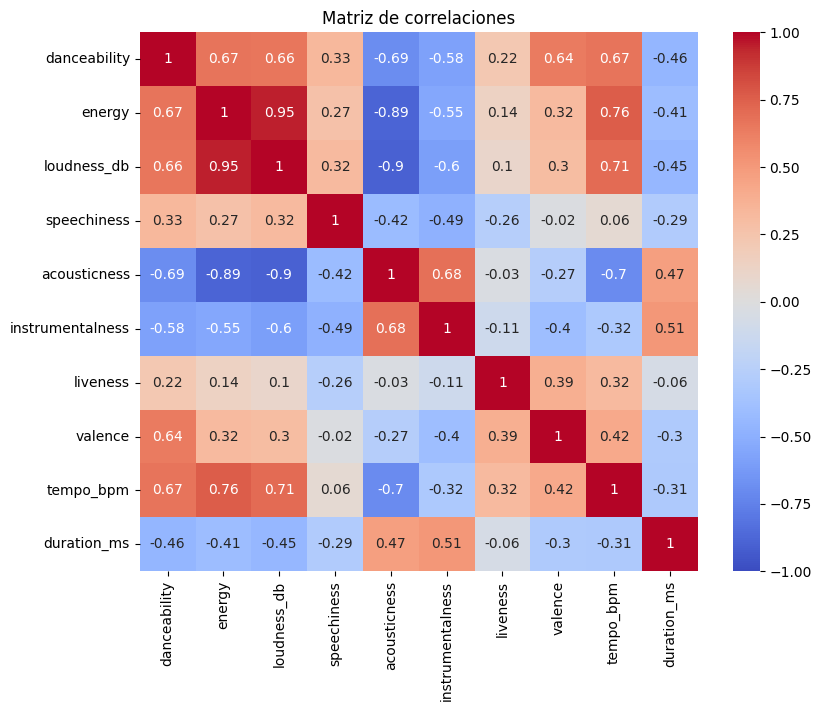

In [2]:
corr = X.corr().round(2)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlaciones')
plt.show()


**Lectura:**

* `energy` y `loudness_db`: **+0.95** (casi la misma información).
* `loudness_db` y `acousticness`: **−0.90**; `energy` y `acousticness`: **−0.89** (las canciones acústicas son suaves).
* `liveness` es la menos relacionada con las demás: su correlación más alta es 0.39 (con `valence`).


## Bloque A3 · ¿Por qué estandarizar? Prueba sin escalar


Aplicamos PCA **directamente** sobre `X`, sin estandarizar, para ver qué pasa.

* `explained_variance_ratio_`: proporción de varianza de cada componente (rango 0 a 1; todas suman 1).
* `components_[0]`: los pesos (loadings) de cada variable en PC1.


In [3]:
from sklearn.decomposition import PCA

pca_sin = PCA(n_components=2).fit(X)        # SIN estandarizar (incorrecto)
print("Varianza explicada:", pca_sin.explained_variance_ratio_.round(3))
pd.Series(pca_sin.components_[0], index=X.columns).round(3)


Varianza explicada: [1. 0.]


,0
danceability,-0.0
energy,-0.0
loudness_db,-0.0
speechiness,-0.0
acousticness,0.0
instrumentalness,0.0
liveness,-0.0
valence,-0.0
tempo_bpm,-0.0
duration_ms,1.0


**Lectura:** sin estandarizar, PC1 explica **≈ 100%** de la varianza y su peso está casi todo en `duration_ms` (≈ 1.0).
No es que la duración sea lo más importante: solo tiene los números más grandes. **Por eso PCA siempre va después de `StandardScaler`**,
que lleva cada variable a media 0 y desviación estándar 1: z = (x − μ) / σ.


## Bloque A4 · `Pipeline` escalar + PCA y varianza explicada


**Librerías:** `Pipeline` y `StandardScaler` (las vimos en clases anteriores).

* `PCA()` sin `n_components` calcula **todas** las componentes (10, una por variable).
* `named_steps['pca']` recupera el paso PCA del `Pipeline` ya entrenado.
* No hay división train/test: PCA no predice ninguna `y`; usamos las 1 200 canciones.


      varianza  acumulada
PC1      0.521      0.521
PC2      0.160      0.681
PC3      0.104      0.785
PC4      0.063      0.848
PC5      0.059      0.907
PC6      0.042      0.949
PC7      0.020      0.969
PC8      0.018      0.987
PC9      0.009      0.996
PC10     0.004      1.000


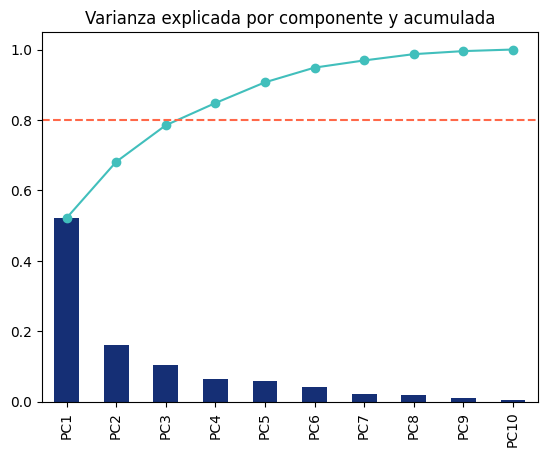

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pca_todas = Pipeline([('escalar', StandardScaler()),
                      ('pca', PCA())])
pca_todas.fit(X)

var = pd.Series(pca_todas.named_steps['pca'].explained_variance_ratio_,
                index=[f'PC{i}' for i in range(1, 11)])
tabla_var = pd.DataFrame({'varianza': var, 'acumulada': var.cumsum()}).round(3)
print(tabla_var)

ax = var.plot(kind='bar', color='#152F75')
ax.plot(var.cumsum().values, marker='o', color='#41BFBC')   # línea de varianza acumulada
ax.axhline(0.80, color='#FF6849', linestyle='--')            # umbral de 80%
ax.set_title('Varianza explicada por componente y acumulada')
plt.show()


**Lectura** (rango 0 a 1 por componente; todas suman 1):

| Componentes | Varianza acumulada |
| --- | --- |
| PC1 | 0.521 |
| PC1–PC2 | 0.681 |
| PC1–PC3 | 0.785 |
| PC1–PC4 | **0.848** → supera el 80% |
| PC1–PC5 | 0.907 → supera el 90% |

PC1 sola resume más de la mitad de la información de las 10 variables.


## Bloque A5 · Elegir k automáticamente con `n_components=0.80`


Si `n_components` es un **decimal entre 0 y 1**, PCA conserva las componentes necesarias para alcanzar ese porcentaje de varianza.
`n_components_` (con guion bajo final) es un **atributo**: solo existe después de `fit()`.


In [5]:
pca_80 = Pipeline([('escalar', StandardScaler()),
                   ('pca', PCA(n_components=0.80))])
pca_80.fit(X)
print("Componentes para el 80%:", pca_80.named_steps['pca'].n_components_)


Componentes para el 80%: 4


**Lectura:** se necesitan **4 componentes** (84.8%). Para un modelo predictivo usaríamos 4;
para **dibujar** las canciones usamos 2 (68.1%), que es lo que haremos a continuación.


## Bloque A6 · Mapa de canciones PC1 vs. PC2


`fit_transform(X)` aprende medias, desviaciones y direcciones, y devuelve las coordenadas de cada canción.
Cada canción pasa de 10 números a 2. Después agregamos el género **solo para colorear**.


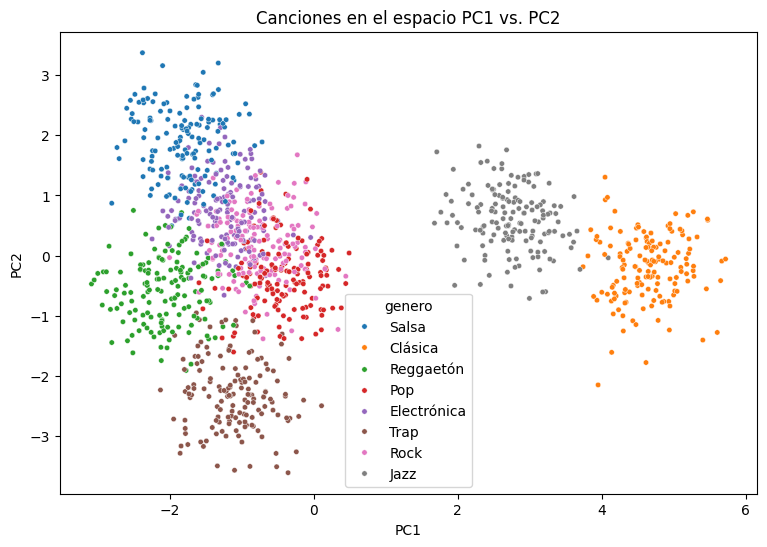

,PC1,PC2
genero,,
Reggaetón,-2.05,-0.58
Salsa,-1.81,1.88
Electrónica,-1.25,0.75
Trap,-1.09,-2.31
Rock,-0.76,0.18
Pop,-0.44,-0.32
Jazz,2.75,0.60
Clásica,4.65,-0.20


In [6]:
pca_pipe = Pipeline([('escalar', StandardScaler()),
                     ('pca', PCA(n_components=2))])
Z = pca_pipe.fit_transform(X)                 # 1 200 filas x 2 columnas

mapa = pd.DataFrame(Z, columns=['PC1', 'PC2'])
mapa['genero'] = generos

plt.figure(figsize=(9, 6))
sns.scatterplot(data=mapa, x='PC1', y='PC2', hue='genero', s=15)
plt.title('Canciones en el espacio PC1 vs. PC2')
plt.show()

centroides = mapa.groupby('genero').mean()    # promedio de cada género
centroides.round(2).sort_values('PC1')


**Lectura** (centroide = promedio de cada género en el mapa):

* **Clásica** (PC1 = 4.65) y **Jazz** (2.75) quedan a la derecha, separados del resto.
* **Reggaetón** (−2.05) y **Salsa** (−1.81) quedan a la izquierda.
* **Trap** queda abajo (PC2 = −2.31) y **Salsa** arriba (PC2 = 1.88).
* PCA **nunca vio** el género: los grupos aparecen solo a partir del perfil sonoro.


## Bloque A7 · Loadings: qué hay dentro de cada componente


`components_` tiene una fila por componente y una columna por variable. Con `.T` (transpuesta) la volteamos:
una fila por variable y una columna por componente. Rango −1 a +1: un valor alejado de 0 indica una variable influyente.


Varianza explicada: [0.521 0.16 ]
                   PC1   PC2
danceability     -0.37  0.11
energy           -0.40 -0.02
loudness_db      -0.40 -0.08
speechiness      -0.18 -0.54
acousticness      0.40  0.16
instrumentalness  0.33  0.17
liveness         -0.09  0.62
valence          -0.23  0.42
tempo_bpm        -0.34  0.25
duration_ms       0.26  0.11


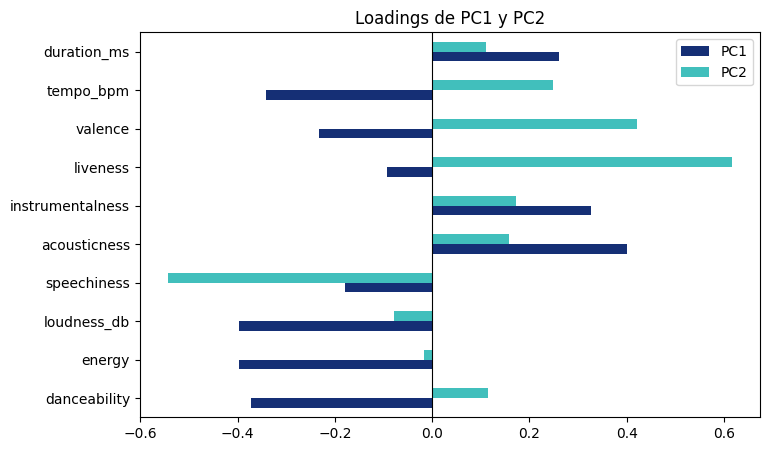

In [7]:
pca = pca_pipe.named_steps['pca']
print("Varianza explicada:", pca.explained_variance_ratio_.round(3))

loadings = pd.DataFrame(pca.components_.T,
                        index=X.columns,
                        columns=['PC1', 'PC2'])
print(loadings.round(2))

loadings.plot(kind='barh', figsize=(8, 5), color=['#152F75', '#41BFBC'])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Loadings de PC1 y PC2')
plt.show()


**Lectura:**

* **PC1:** positivos `acousticness` (+0.40), `instrumentalness` (+0.33) y `duration_ms` (+0.26);
  negativos `energy` y `loudness_db` (−0.40), `danceability` (−0.37) y `tempo_bpm` (−0.34).
  → **Eje acústico (+) vs. energético (−)**. Por eso Clásica y Jazz están a la derecha.
* **PC2:** positivos `liveness` (+0.62) y `valence` (+0.42); negativo `speechiness` (−0.54).
  → **En vivo y alegre (+) vs. voz hablada (−)**. Por eso Trap está abajo y Salsa arriba.

> **Ojo:** el signo de una componente es arbitrario. Otra versión de scikit-learn u otro programa puede invertir todos sus signos.
> Ejemplo real con este dataset: con scikit-learn **anterior a 1.5**, PC2 sale con el signo opuesto (`liveness` = −0.62,
> Trap arriba y Salsa abajo). El mapa se ve reflejado, pero la interpretación es la misma.

> **Nota de vocabulario:** en este curso llamamos *loadings* a los valores de `components_` (los pesos de cada variable).
> Algunos libros de estadística reservan ese nombre para esos pesos multiplicados por la desviación estándar de la componente;
> la interpretación (signo y tamaño relativo) es la misma.


## Bloque A8 · Biplot


El biplot dibuja en el mismo gráfico las canciones (puntos) y una flecha por variable con sus loadings.
Multiplicamos los loadings por 4 **solo para que las flechas se vean** junto a los puntos.


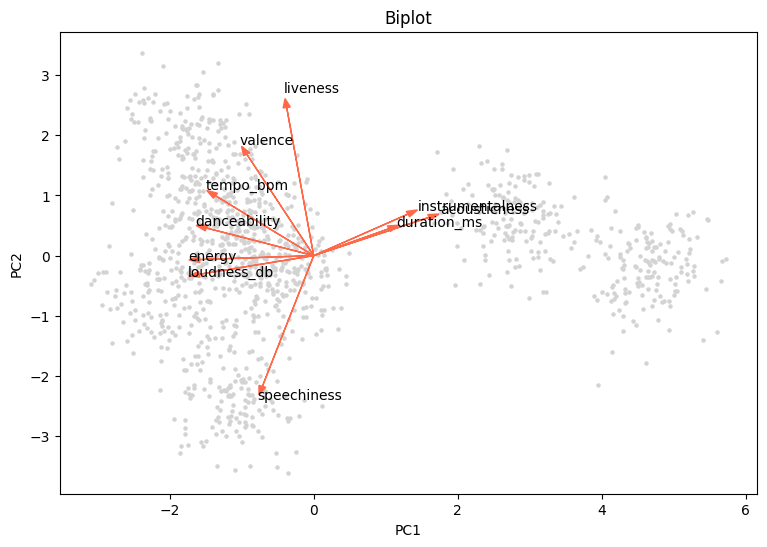

In [8]:
plt.figure(figsize=(9, 6))
plt.scatter(mapa['PC1'], mapa['PC2'], s=5, color='lightgray')
for variable in X.columns:
    x, y = loadings.loc[variable] * 4
    plt.arrow(0, 0, x, y, color='#FF6849', head_width=0.1)
    plt.text(x * 1.1, y * 1.1, variable)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Biplot')
plt.show()


**Cómo leerlo:**

* Flecha larga = variable influyente en PC1 y PC2.
* Flechas en la misma dirección = correlación positiva (`energy` y `loudness_db` casi se superponen: r = 0.95).
* Flechas opuestas = correlación negativa (`acousticness` frente a `energy`).
* Flechas perpendiculares = variables sin relación.
* Es una lectura **aproximada**: el plano PC1–PC2 solo muestra el 68.1% de la varianza.


# Parte B — Práctica Autónoma: ¿Ritmo o Timbre?


**Contexto:** las 10 variables pueden separarse en dos grupos según lo que miden. Quieres saber cuál grupo
resume mejor la información y cuál separa mejor los géneros.

| Grupo | Variables | Qué captura |
| --- | --- | --- |
| Ritmo e intensidad | `danceability`, `energy`, `loudness_db`, `tempo_bpm`, `valence` | Qué tan enérgica, bailable y alegre es |
| Timbre y textura | `acousticness`, `instrumentalness`, `speechiness`, `liveness`, `duration_ms` | Cómo suena: acústica, instrumental, hablada o en vivo |

En **tu propio notebook**, escribe el código que reemplace cada `# TODO` que ves en esta guía y responde
las preguntas en una celda de texto. Sigue la misma secuencia de la Parte A.


## Bloque B1 · Dos PCA por separado


In [9]:
cols_ritmo = ['danceability', 'energy', 'loudness_db', 'tempo_bpm', 'valence']
cols_timbre = ['acousticness', 'instrumentalness', 'speechiness', 'liveness', 'duration_ms']

# TODO 1: crea X_ritmo y X_timbre seleccionando esas columnas de df (pista: df[cols_ritmo])
X_ritmo = df[cols_ritmo]
X_timbre = df[cols_timbre]

# TODO 2: crea pipe_ritmo y pipe_timbre, dos Pipeline iguales al del Bloque A6
#         (StandardScaler + PCA con 2 componentes)
pipe_ritmo = Pipeline([('escalar', StandardScaler()),
                       ('pca', PCA(n_components=2))])

pipe_timbre = Pipeline([('escalar', StandardScaler()),
                        ('pca', PCA(n_components=2))])

# TODO 3: entrena cada Pipeline con su grupo usando fit_transform y guarda Z_ritmo y Z_timbre
#         Verifica que cada uno tenga forma (1200, 2)
Z_ritmo = pipe_ritmo.fit_transform(X_ritmo)
Z_timbre = pipe_timbre.fit_transform(X_timbre)

print("Forma Z_ritmo: ", Z_ritmo.shape)
print("Forma Z_timbre:", Z_timbre.shape)


Forma Z_ritmo:  (1200, 2)
Forma Z_timbre: (1200, 2)


## Bloque B2 · Comparar la varianza explicada


In [10]:
# TODO 4: con named_steps['pca'], muestra explained_variance_ratio_ de cada grupo
#         y su suma (varianza acumulada de PC1 + PC2)
pca_r = pipe_ritmo.named_steps['pca']
pca_t = pipe_timbre.named_steps['pca']

var_r = pca_r.explained_variance_ratio_
var_t = pca_t.explained_variance_ratio_

print("Ritmo e intensidad:")
print(f"  PC1: {var_r[0]:.3f} | PC2: {var_r[1]:.3f} | Acumulada PC1+PC2: {var_r.sum():.3f}")

print("\nTimbre y textura:")
print(f"  PC1: {var_t[0]:.3f} | PC2: {var_t[1]:.3f} | Acumulada PC1+PC2: {var_t.sum():.3f}")


Ritmo e intensidad:
  PC1: 0.699 | PC2: 0.182 | Acumulada PC1+PC2: 0.881

Timbre y textura:
  PC1: 0.489 | PC2: 0.233 | Acumulada PC1+PC2: 0.722


**Completa la tabla con tus resultados:**

| Grupo | Varianza PC1 | Varianza PC2 | Acumulada PC1 + PC2 |
| --- | --- | --- | --- |
| Ritmo e intensidad | 0.699 | 0.182 | 0.881 |
| Timbre y textura | 0.489 | 0.233 | 0.722 |
| Las 10 variables (Parte A) | 0.521 | 0.160 | 0.681 |

**Preguntas:**

1. ¿En qué grupo explican más varianza las 2 primeras componentes? ¿Por qué crees que ocurre? (Pista: revisa la matriz de correlaciones del Bloque A2.)

Las dos primeras componentes explican mas varianza en el grupo de ritmo e intensidad, alcanzando un 88.1% acumulado frente al 72.2% del grupo de timbre. Esto ocurre porque las variables de ritmo e intensidad presentan correlaciones lineales mucho mas fuertes entre si por ejemplo, energy y loudness tienen una correlacion de 0.95, y ambas correlacionan fuertemente con danceability y tempo, lo que significa que comparten mucha informacion redundante y PCA puede comprimirlas facilmente en muy pocas dimensiones. En cambio, en el grupo de timbre las variables son mas independientes y diversas como liveness y duration ms, obligando a repartir la varianza en mas componentes.

2. ¿Por qué ambos grupos acumulan más varianza con 2 componentes que las 10 variables juntas?

Ocurre porque cada subgrupo tiene solo 5 variables originales en lugar de 10. Conservar 2 componentes de un total de 5 representa retener el 40% de las dimensiones posibles del espacio, mientras que 2 componentes de 10 representan apenas el 20%. Al haber menos variables y dimensiones ortogonales totales en cada subgrupo, 2 componentes logran capturar una proporcion relativa de varianza mucho mayor.

3. ¿Más varianza explicada significa siempre que el grupo separa mejor los géneros? Responde después de hacer el Bloque B3.

No necesariamente, ya que el PCA es una tecnica no supervisada que busca maximizar la dispersion o varianza global de los datos sin conocer las etiquetas de las clases o generos. Un grupo puede tener alta varianza explicada debido a fuertes correlaciones internas, pero si esa variabilidad no coincide con las diferencias sonoras reales entre generos por ejemplo, la separacion entre musica clasica y musica urbana, los grupos quedaran superpuestos en el mapa. La capacidad de separacion depende de la relevancia tematica de las variables para distinguir las clases, no solo del porcentaje matematico de varianza explicada.


## Bloque B3 · Comparar los mapas y los loadings


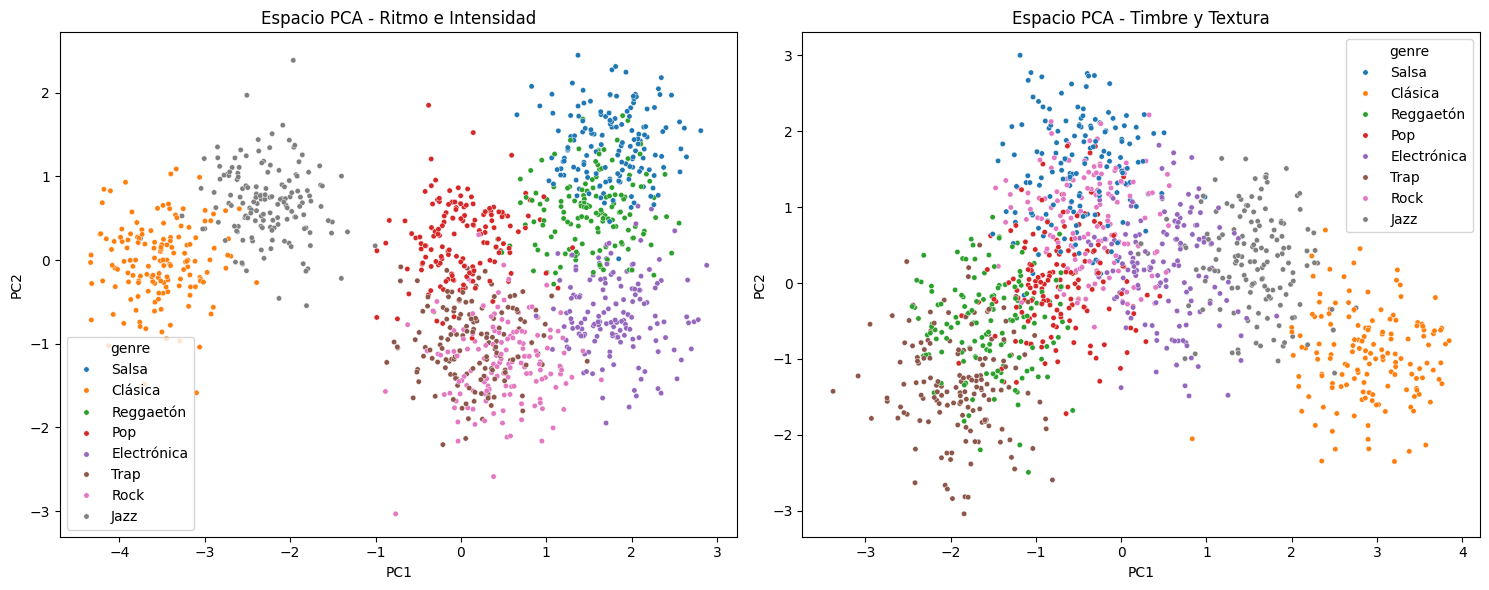

=== LOADINGS: RITMO E INTENSIDAD ===


,PC1,PC2
danceability,0.46,0.30
energy,0.49,-0.34
loudness_db,0.48,-0.37
tempo_bpm,0.46,-0.10
valence,0.32,0.80



=== LOADINGS: TIMBRE Y TEXTURA ===


,PC1,PC2
acousticness,0.54,-0.08
instrumentalness,0.56,-0.13
speechiness,-0.44,-0.44
liveness,0.01,0.86
duration_ms,0.46,-0.18


In [11]:
# TODO 5: crea la figura con dos gráficos: fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#         y en axes[0] dibuja el mapa de Z_ritmo coloreado por género
#         pista: sns.scatterplot(x=Z_ritmo[:, 0], y=Z_ritmo[:, 1], hue=generos, s=12, ax=axes[0])
# TODO 6: en axes[1] dibuja el mapa de Z_timbre de la misma forma, pon un título a cada gráfico
#         y termina con plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(x=Z_ritmo[:, 0], y=Z_ritmo[:, 1], hue=generos, s=15, ax=axes[0])
axes[0].set_title('Espacio PCA - Ritmo e Intensidad')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

sns.scatterplot(x=Z_timbre[:, 0], y=Z_timbre[:, 1], hue=generos, s=15, ax=axes[1])
axes[1].set_title('Espacio PCA - Timbre y Textura')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

# TODO 7: muestra la tabla de loadings de cada grupo (igual que en el Bloque A7,
#         con index=cols_ritmo o index=cols_timbre)
loadings_ritmo = pd.DataFrame(pca_r.components_.T, index=cols_ritmo, columns=['PC1', 'PC2'])
loadings_timbre = pd.DataFrame(pca_t.components_.T, index=cols_timbre, columns=['PC1', 'PC2'])

print("=== LOADINGS: RITMO E INTENSIDAD ===")
display(loadings_ritmo.round(2))

print("\n=== LOADINGS: TIMBRE Y TEXTURA ===")
display(loadings_timbre.round(2))


**Preguntas:**

1. ¿Qué grupo separa mejor a Clásica y Jazz del resto? ¿Y a Trap? Justifica con lo que ves en los mapas.

El grupo de timbre y textura separa mejor a Clasica y Jazz del resto porque estas musicas se caracterizan principalmente por su naturaleza acustica e instrumental, lo que las ubicaen el extremo derecho de PC1 con centroides en 2.90 y 1.56. Asimismo, el grupo de timbre tambien separa mucho mejor a Trap, ubicandolo de forma aislada en la esquina inferior izquierda en el centroide en -1.89 en PC1 y -1.34 en PC2 debido a su alto nivel de palabras habladas. En cambio, en el mapa de ritmo, Trap se mezcla considerablemente con Pop y Rock en el centro.

2. Con los loadings: ¿qué variable domina la PC1 de cada grupo? ¿Cómo describirías en una frase el significado de cada PC1?

En el grupo de ritmo e intensidad, la variable que mas domina PC1 es energy con un loading de 0.49, seguida de cerca por loudness db (0.48), danceability (0.46) y tempo bpm (0.46); esta PC1 representa un eje general de dinamismo y potencia bailable frente a canciones lentas y suaves. En el grupo de timbre y textura, la variable que mas domina PC1 es instrumentalness con  0.56 seguida de acousticness (0.54) y en sentido opuesto speechiness (-0.44). Esta PC1 describe un eje acustico e instrumental puro frente a producciones vocales y procesadas.

3. Con base en todo el taller: ¿preferirías usar las 10 variables o solo un grupo para construir un mapa de canciones? Da una razón.

Preferiria utilizar las 10 variables completas porque cada grupo aporta informacion complementaria indispensable: el ritmo permite distinguir el grado de baile, alegria y cadencia separando por ejemplo Salsa y Reggaeton, mientras que el timbre aporta la distincion esencial entre musica acustica, electronica o cantada separando Clasica, Jazz y Trap. Integrar ambos aspectos genera una representacion global mucho mas rica donde cada genero musical encuentra su propio espacio caracteristico.

4. Reflexion: el dataset es sintético. ¿Qué limitación tiene este análisis frente a datos reales de Spotify?

En un dataset sintetico las variables suelen tener distribuciones limpias, correlaciones ideales y generos perfectamente balanceados con 150 canciones cada uno sin valores nulos ni ruido complejo. En los datos reales de la API de Spotify existe una enorme heterogeneidad dentro de un mismo genero, fusiones hibridas modernas, grabaciones en vivo con mala acustica, canciones cortas o interludios, y un fuerte desbalance donde ciertos generos son exponencialmente mas comunes que otros, lo que haria que los agrupamientos en PCA fueran mucho mas dispersos, solapados y dificiles de separar limpiamente.


# Bloque C — Entrenamiento Final, Exportación y Uso con Canciones Nuevas


**Idea central:** en PCA no hubo división train/test, así que el análisis ya usó el 100% de las canciones.
El **modelo final** repite ese ajuste con las 1 200 canciones y agrega un paso más para usarlo con datos nuevos:
ubicar cada canción nueva en el mapa y decir a qué género queda **más cerca**.


## C.1 · Reentrenar con el 100% de los datos


**Librería nueva:** `NearestCentroid` calcula el **centroide** (promedio) de cada género y asigna cada canción
al género cuyo centroide está más cerca. Usamos sus valores por defecto (distancia euclidiana).

* **Análisis (exploración):** `pca_pipe`; sirvió para entender la varianza, los loadings y el mapa.
* **Modelo final (100%):** `modelo_final` = escalar + PCA + género cercano, entrenado con `X` y `generos` completos.

> **Ojo:** PCA no usa el género; `NearestCentroid` sí lo usa para calcular los centroides. Aquí es una **referencia
> de cercanía en el mapa**, no un clasificador evaluado con métricas.


In [12]:
from sklearn.neighbors import NearestCentroid

modelo_final = Pipeline([('escalar', StandardScaler()),
                         ('pca', PCA(n_components=2)),
                         ('genero', NearestCentroid())])
modelo_final.fit(X, generos)          # 100%: las 1 200 canciones
print("modelo_final entrenado con", len(X), "canciones.")


modelo_final entrenado con 1200 canciones.


## C.2 · Exportar el modelo con `joblib`


`joblib` guarda el **Pipeline completo** (escalador, PCA y centroides) en un solo archivo `.pkl`.

> Carga el `.pkl` con la **misma versión de scikit-learn** con la que se guardó.


In [13]:
import joblib

joblib.dump(modelo_final, 'modelo_pca_spotify.pkl')
print("Modelo exportado a modelo_pca_spotify.pkl")


Modelo exportado a modelo_pca_spotify.pkl


## C.3 · Usar el modelo con canciones nuevas


Así se usaría el archivo **desde otro programa** (por ejemplo, una API: un servicio web que recibe los datos y devuelve el resultado).
El DataFrame lleva las **mismas 10 columnas** de `X`, con los mismos nombres, **sin estandarizar**: el `Pipeline` lo hace solo.

* `modelo[:-1]` = todos los pasos **menos el último** (escalar + PCA) → `transform()` da las coordenadas PC1 y PC2.
* `modelo.predict()` recorre los 3 pasos → devuelve el género más cercano.


In [14]:
import joblib
import pandas as pd

modelo = joblib.load('modelo_pca_spotify.pkl')

nuevas = pd.DataFrame({
    'danceability': [0.30, 0.88, 0.72],
    'energy': [0.25, 0.82, 0.62],
    'loudness_db': [-22.0, -8.5, -10.0],
    'speechiness': [0.03, 0.12, 0.33],
    'acousticness': [0.85, 0.08, 0.12],
    'instrumentalness': [0.80, 0.01, 0.02],
    'liveness': [0.12, 0.15, 0.11],
    'valence': [0.25, 0.80, 0.40],
    'tempo_bpm': [95, 98, 140],
    'duration_ms': [215000, 180000, 170000]},
    index=['Canción A', 'Canción B', 'Canción C'])

resultado = pd.DataFrame(modelo[:-1].transform(nuevas),
                         columns=['PC1', 'PC2'], index=nuevas.index)
resultado['genero_cercano'] = modelo.predict(nuevas)
resultado.round(2)


,PC1,PC2,genero_cercano
Canción A,4.72,-0.55,Clásica
Canción B,-1.56,-0.35,Reggaetón
Canción C,-1.51,-2.49,Trap


Ubicamos las canciones nuevas (estrellas) sobre el mapa de la Parte A, junto con los centroides de cada género.
Podemos mezclar ambos porque `modelo_final` se entrenó con **exactamente los mismos datos** que `pca_pipe`:
aprendió las mismas medias y las mismas direcciones, así que el mapa es el mismo.


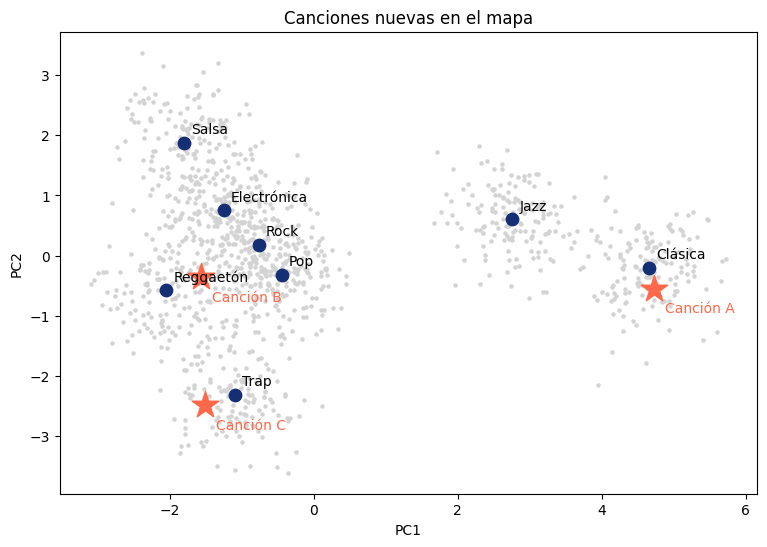

In [15]:
plt.figure(figsize=(9, 6))
plt.scatter(mapa['PC1'], mapa['PC2'], s=5, color='lightgray')
plt.scatter(centroides['PC1'], centroides['PC2'], s=80, color='#152F75')
for genero, fila in centroides.iterrows():
    plt.text(fila['PC1'] + 0.1, fila['PC2'] + 0.15, genero)
plt.scatter(resultado['PC1'], resultado['PC2'], marker='*', s=400, color='#FF6849')
for nombre, fila in resultado.iterrows():
    plt.text(fila['PC1'] + 0.15, fila['PC2'] - 0.4, nombre, color='#FF6849')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Canciones nuevas en el mapa')
plt.show()


**Lectura:**

* **Canción A** (acústica e instrumental) → PC1 ≈ 4.72 → junto a **Clásica**.
* **Canción B** (bailable y enérgica) → (−1.56, −0.35) → junto a **Reggaetón**.
* **Canción C** (mucha voz hablada: 0.33) → PC2 ≈ −2.49 → junto a **Trap**.
* Las canciones nuevas se proyectan con las **mismas medias y direcciones** aprendidas con las 1 200 canciones: no se vuelve a entrenar nada.


## Conclusiones


* PCA es **no supervisado**: resume muchas variables en pocas componentes nuevas sin usar ninguna `y`.
* Siempre se **estandariza** antes: sin escalar, la variable con números más grandes (`duration_ms`) domina todo.
* La **varianza explicada** indica cuánta información conserva cada componente; `n_components=0.80` elige k solo.
* Los **loadings** dan significado a cada componente: PC1 = acústico vs. energético; PC2 = en vivo y alegre vs. voz hablada.
* El **mapa** y el **biplot** permiten ver 10 variables en 2 dimensiones.
* El modelo final se entrena con el 100% de los datos, se exporta con `joblib` (Pipeline completo) y se usa con datos crudos.
